
# Projet Data Mining : Catastrophes Naturelles

# Nom et Prénom : Sarra Askri 






## 1. Importation des bibliothèques



In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix



## 2. Lecture des données

Nous chargeons le fichier CSV puis nous nettoyons les noms des colonnes afin d'éviter les problèmes liés aux espaces et aux caractères spéciaux.


In [2]:

# Étape 1 : Lecture des données

# Si le fichier CSV est dans le même dossier que le notebook :
df = pd.read_csv("natural_disasters.csv")

# Si nécessaire, vous pouvez utiliser le chemin complet :
# df = pd.read_csv("C:/Users/TBAR9A/Desktop/data_mining/natural_disasters.csv")

# Nettoyage des noms de colonnes
df.columns = df.columns.str.strip().str.replace(" ", "_") \
                       .str.replace("(", "", regex=False).str.replace(")", "", regex=False) \
                       .str.replace("'", "", regex=False)

print("Dimensions :", df.shape)
df.head()


Dimensions : (16126, 45)


,Year,Seq,Glide,Disaster_Group,Disaster_Subgroup,Disaster_Type,Disaster_Subtype,Disaster_Subsubtype,Event_Name,Country,...,No_Affected,No_Homeless,Total_Affected,Insured_Damages_000_US$,Total_Damages_000_US$,CPI,Adm_Level,Admin1_Code,Admin2_Code,Geo_Locations
0,1900,9002,NaN,Natural,Climatological,Drought,Drought,NaN,NaN,Cabo Verde,...,NaN,NaN,NaN,NaN,NaN,3.221647,NaN,NaN,NaN,NaN
1,1900,9001,NaN,Natural,Climatological,Drought,Drought,NaN,NaN,India,...,NaN,NaN,NaN,NaN,NaN,3.221647,NaN,NaN,NaN,NaN
2,1902,12,NaN,Natural,Geophysical,Earthquake,Ground movement,NaN,NaN,Guatemala,...,NaN,NaN,NaN,NaN,25000.0,3.350513,NaN,NaN,NaN,NaN
3,1902,3,NaN,Natural,Geophysical,Volcanic activity,Ash fall,NaN,Santa Maria,Guatemala,...,NaN,NaN,NaN,NaN,NaN,3.350513,NaN,NaN,NaN,NaN
4,1902,10,NaN,Natural,Geophysical,Volcanic activity,Ash fall,NaN,Santa Maria,Guatemala,...,NaN,NaN,NaN,NaN,NaN,3.350513,NaN,NaN,NaN,NaN



## 3. Renommage des colonnes importantes

Nous renommons la colonne des dégâts économiques pour faciliter son utilisation dans le code.


In [3]:
# Étape 2 : Renommer les colonnes importantes

df.rename(columns={
    "Total_Damages_000_US$": "Damage_Thousands_USD"
}, inplace=True)

required_columns = ["Year", "Disaster_Type", "Total_Deaths", "Damage_Thousands_USD"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise KeyError(f"Colonnes attendues absentes du dataset : {missing_columns}")

df[required_columns].head()


,Year,Disaster_Type,Total_Deaths,Damage_Thousands_USD
0,1900,Drought,11000.0,NaN
1,1900,Drought,1250000.0,NaN
2,1902,Earthquake,2000.0,25000.0
3,1902,Volcanic activity,1000.0,NaN
4,1902,Volcanic activity,6000.0,NaN



## 4. Gestion des valeurs manquantes

Les valeurs manquantes sont traitées comme suit :

- `Total_Deaths` : remplacement par la médiane.
- `Damage_Thousands_USD` : remplacement par 0.


In [4]:
# Étape 3 : Gestion des valeurs manquantes

# Convertir les colonnes en valeurs numériques lorsque c'est possible.
df["Total_Deaths"] = pd.to_numeric(df["Total_Deaths"], errors="coerce")
df["Damage_Thousands_USD"] = pd.to_numeric(
    df["Damage_Thousands_USD"], errors="coerce"
)

# La cible Severe dépend directement du nombre de décès :
# on ne peut pas attribuer une classe fiable si cette valeur est inconnue.
rows_before = len(df)
df = df.dropna(subset=["Total_Deaths"]).copy()
print("Lignes supprimées car le nombre de décès est inconnu :", rows_before - len(df))

# Hypothèse conservée du projet initial : les dommages manquants sont remplacés par 0.
# À justifier dans le rapport, car une valeur manquante ne signifie pas toujours zéro dommage.
df["Damage_Thousands_USD"] = df["Damage_Thousands_USD"].fillna(0)

print(df[["Total_Deaths", "Damage_Thousands_USD"]].isnull().sum())


Lignes supprimées car le nombre de décès est inconnu : 4713
Total_Deaths            0
Damage_Thousands_USD    0
dtype: int64



## 5. Suppression des doublons et correction des types

Nous supprimons les doublons et nous transformons la colonne `Year` en type entier.


In [5]:
# Étape 4 : Suppression des doublons et correction des types
df = df.drop_duplicates()
# Convertir Year de manière sûre et retirer les lignes sans année exploitable.
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
rows_before = len(df)
df = df.dropna(subset=["Year"]).copy()
print("Lignes supprimées car l'année est manquante/invalide :", rows_before - len(df))
df["Year"] = df["Year"].astype(int)
print("Dimensions après nettoyage :", df.shape)
print("Type de Year :", df["Year"].dtype)


Lignes supprimées car l'année est manquante/invalide : 0
Dimensions après nettoyage : (11413, 45)
Type de Year : int64



## 6. Création de la variable cible

Nous créons la variable `Severe`.

Une catastrophe est considérée comme sévère si le nombre total de décès est supérieur à 100.

Cette variable sera utilisée dans la partie classification.


In [6]:

# Étape 6 : Création de la variable cible

df["Severe"] = df["Total_Deaths"].apply(lambda x: 1 if x > 100 else 0)

print("--- Distribution de la variable cible Severe ---")
print(df["Severe"].value_counts())
print(df["Severe"].value_counts(normalize=True))


--- Distribution de la variable cible Severe ---
Severe
0    9342
1    2071
Name: count, dtype: int64
Severe
0    0.81854
1    0.18146
Name: proportion, dtype: float64


## 7. Traitement des valeurs aberrantes

Au lieu de supprimer les valeurs extrêmes, nous utilisons le **capping** pour limiter leur influence dans certaines analyses.

Le capping ne garantit pas l'équilibre de la variable cible. La cible `Severe` est définie séparément à partir du nombre de décès avant la création de la variable plafonnée.


In [7]:

# Étape 7 : Traitement des outliers avec capping

Q1 = df["Total_Deaths"].quantile(0.25)
Q3 = df["Total_Deaths"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df["Total_Deaths_Capped"] = df["Total_Deaths"].clip(lower=lower_bound, upper=upper_bound)
print("Maximum avant capping :", df["Total_Deaths"].max())
print("Maximum après capping :", df["Total_Deaths_Capped"].max())


Maximum avant capping : 3700000.0
Maximum après capping : 148.5


## 8. Feature Engineering

Nous créons les variables suivantes :

- `Decade` : décennie de l'événement.
- `Damage_Log` : transformation logarithmique des dommages économiques exprimés en milliers de dollars, afin de réduire l'effet des grandes valeurs.

La définition de la variable cible `Severe` est : 1 si le nombre de décès est supérieur à 100, sinon 0.


In [8]:

# Étape 8 : Feature Engineering

df["Decade"] = (df["Year"] // 10) * 10
df["Damage_Log"] = np.log1p(df["Damage_Thousands_USD"])

df[["Year", "Decade", "Total_Deaths", "Total_Deaths_Capped", "Damage_Thousands_USD", "Damage_Log", "Severe"]].head()


,Year,Decade,Total_Deaths,Total_Deaths_Capped,Damage_Thousands_USD,Damage_Log,Severe
0,1900,1900,11000.0,148.5,0.0,0.000000,1
1,1900,1900,1250000.0,148.5,0.0,0.000000,1
2,1902,1900,2000.0,148.5,25000.0,10.126671,1
3,1902,1900,1000.0,148.5,0.0,0.000000,1
4,1902,1900,6000.0,148.5,0.0,0.000000,1



## 9. Encodage des variables catégorielles

La variable `Disaster_Type` est textuelle.  
Nous la transformons en variables numériques avec `get_dummies`.


In [9]:

# Étape 9 : Encodage

df = pd.get_dummies(df, columns=["Disaster_Type"], drop_first=True)

df.head()


,Year,Seq,Glide,Disaster_Group,Disaster_Subgroup,Disaster_Subtype,Disaster_Subsubtype,Event_Name,Country,ISO,...,Disaster_Type_Epidemic,Disaster_Type_Extreme temperature,Disaster_Type_Flood,Disaster_Type_Fog,Disaster_Type_Glacial lake outburst,Disaster_Type_Landslide,Disaster_Type_Mass movement (dry),Disaster_Type_Storm,Disaster_Type_Volcanic activity,Disaster_Type_Wildfire
0,1900,9002,NaN,Natural,Climatological,Drought,NaN,NaN,Cabo Verde,CPV,...,False,False,False,False,False,False,False,False,False,False
1,1900,9001,NaN,Natural,Climatological,Drought,NaN,NaN,India,IND,...,False,False,False,False,False,False,False,False,False,False
2,1902,12,NaN,Natural,Geophysical,Ground movement,NaN,NaN,Guatemala,GTM,...,False,False,False,False,False,False,False,False,False,False
3,1902,3,NaN,Natural,Geophysical,Ash fall,NaN,Santa Maria,Guatemala,GTM,...,False,False,False,False,False,False,False,False,True,False
4,1902,10,NaN,Natural,Geophysical,Ash fall,NaN,Santa Maria,Guatemala,GTM,...,False,False,False,False,False,False,False,False,True,False



## 10. Analyse de distribution

Nous analysons les variables principales à l'aide de statistiques descriptives, d'histogrammes et de boîtes à moustaches.


--- Analyse de distribution ---
       Total_Deaths  Total_Deaths_Capped  Damage_Thousands_USD    Damage_Log
count  1.141300e+04         11413.000000          1.141300e+04  11413.000000
mean   2.842866e+03            44.066854          3.016891e+05      3.909927
std    6.860595e+04            51.556452          3.207218e+06      5.477968
min    1.000000e+00             1.000000          0.000000e+00      0.000000
25%    6.000000e+00             6.000000          0.000000e+00      0.000000
50%    2.000000e+01            20.000000          0.000000e+00      0.000000
75%    6.300000e+01            63.000000          1.600000e+04      9.680406
max    3.700000e+06           148.500000          2.100000e+08     19.162618


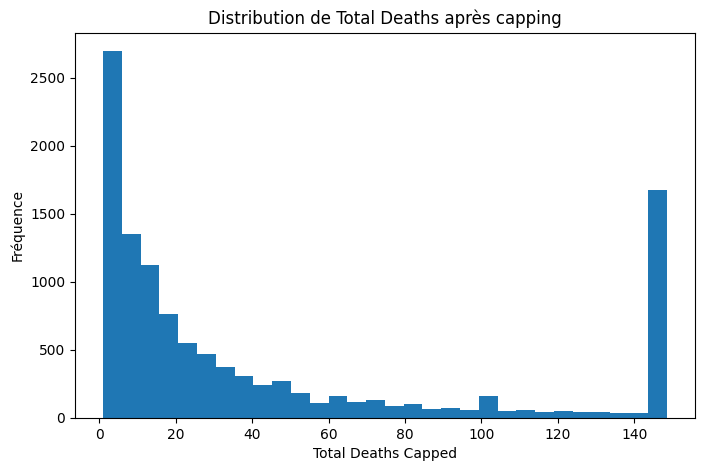

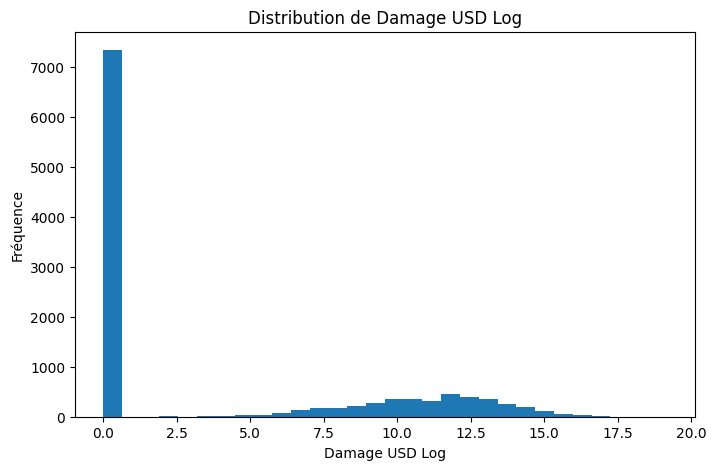

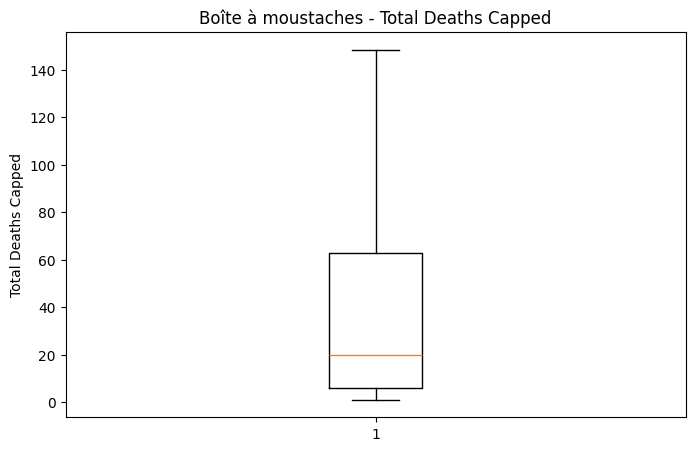

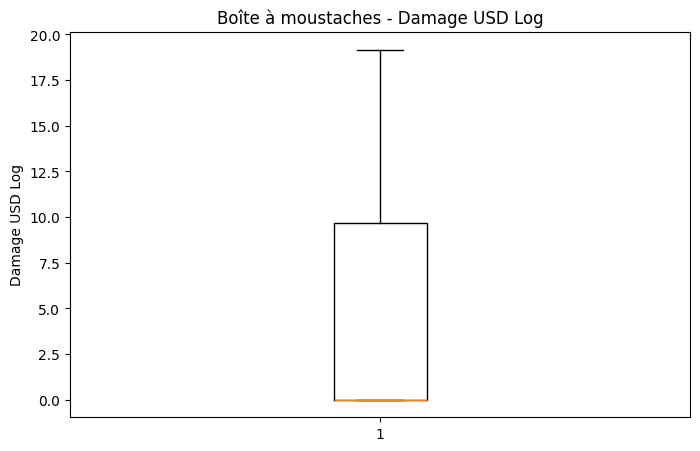

In [10]:

# Étape 10 : Analyse de distribution

print("--- Analyse de distribution ---")
print(df[["Total_Deaths", "Total_Deaths_Capped", "Damage_Thousands_USD", "Damage_Log"]].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["Total_Deaths_Capped"], bins=30)
plt.title("Distribution de Total Deaths après capping")
plt.xlabel("Total Deaths Capped")
plt.ylabel("Fréquence")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df["Damage_Log"], bins=30)
plt.title("Distribution de Damage USD Log")
plt.xlabel("Damage USD Log")
plt.ylabel("Fréquence")
plt.show()

plt.figure(figsize=(8, 5))
plt.boxplot(df["Total_Deaths_Capped"].dropna())
plt.title("Boîte à moustaches - Total Deaths Capped")
plt.ylabel("Total Deaths Capped")
plt.show()

plt.figure(figsize=(8, 5))
plt.boxplot(df["Damage_Log"].dropna())
plt.title("Boîte à moustaches - Damage USD Log")
plt.ylabel("Damage USD Log")
plt.show()



# Partie 1 : Clustering avec KMeanss

Le clustering est une méthode non supervisée.  
Dans cette partie, nous utilisons KMeanss pour regrouper les catastrophes naturelles similaires.

Pour éviter de choisir le nombre de clusters au hasard, nous testons plusieurs valeurs de `k`.



## 11. Préparation des variables pour le clustering

Pour le clustering, nous utilisons des variables descriptives :

- `Total_Deaths_Capped`
- `Damage_Log`
- `Year`
- `Decade`
- les colonnes issues du type de catastrophe


In [11]:
# Étape 11 : Préparation des variables pour le clustering
disaster_type_columns = [  col for col in df.columns if col.startswith("Disaster_Type_")]
clustering_features = [ "Total_Deaths_Capped", "Damage_Log", "Year"] + disaster_type_columns
X_clustering = df[clustering_features]
scaler_clustering = StandardScaler()
X_clustering_scaled = scaler_clustering.fit_transform(X_clustering)
print("Nombre de variables pour le clustering :", len(clustering_features))


Nombre de variables pour le clustering : 15



## 12. Recherche du meilleur nombre de clusters

Nous testons plusieurs valeurs de `k` entre 2 et 8.

Nous utilisons :

- **Inertie** : plus elle est faible, plus les points sont proches des centres.
- **Silhouette Score** : plus il est proche de 1, meilleure est la séparation des clusters.


In [12]:

# Étape 12 : Recherche du meilleur k
k_values = range(2, 9)
inertias = []
silhouette_scores = []
for k in k_values:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_temp = kmeans_temp.fit_predict(X_clustering_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(X_clustering_scaled, labels_temp))
kmeans_results = pd.DataFrame({
    "k": list(k_values),
    "Inertie": inertias,
    "Silhouette Score": silhouette_scores
})

kmeans_results


,k,Inertie,Silhouette Score
0,2,154656.383105,0.154306
1,3,139887.526314,0.242449
2,4,126422.816950,0.314325
3,5,113310.506292,0.382750
4,6,100438.143041,0.446322
5,7,88844.152333,0.462518
6,8,77224.893245,0.482470



## 13. Visualisation du choix de k

Nous affichons deux graphiques :

- la méthode du coude avec l'inertie,
- le Silhouette Score selon le nombre de clusters.


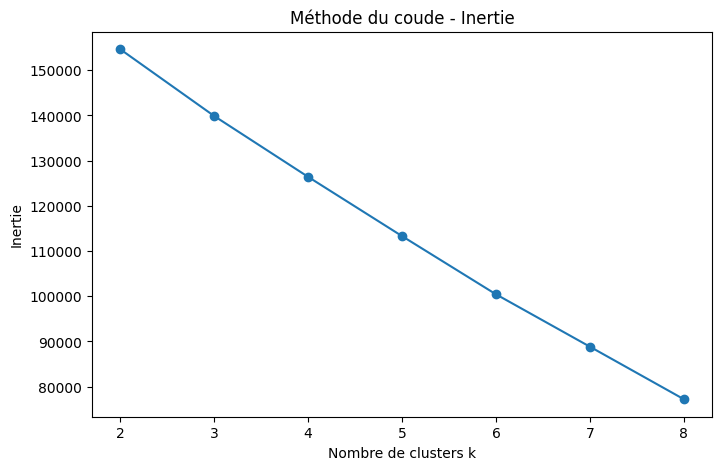

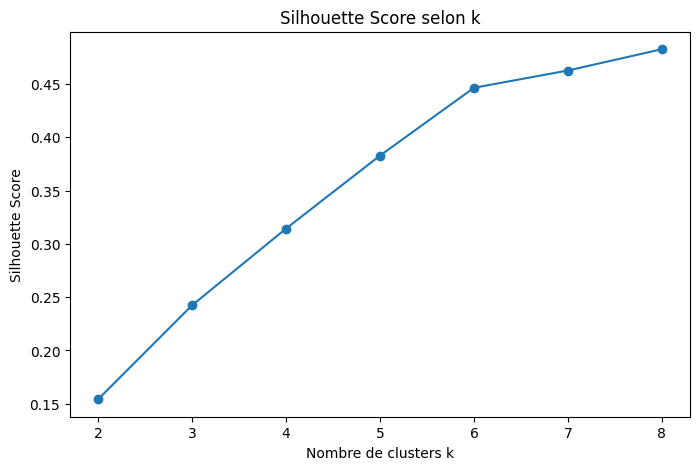

Meilleur nombre de clusters selon Silhouette Score : 8


In [13]:

# Étape 13 : Visualisation du choix de k

plt.figure(figsize=(8, 5))
plt.plot(kmeans_results["k"], kmeans_results["Inertie"], marker="o")
plt.title("Méthode du coude - Inertie")
plt.xlabel("Nombre de clusters k")
plt.ylabel("Inertie")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(kmeans_results["k"], kmeans_results["Silhouette Score"], marker="o")
plt.title("Silhouette Score selon k")
plt.xlabel("Nombre de clusters k")
plt.ylabel("Silhouette Score")
plt.show()

best_k = int(kmeans_results.sort_values(by="Silhouette Score", ascending=False).iloc[0]["k"])
print("Meilleur nombre de clusters selon Silhouette Score :", best_k)



## 14. Application finale de KMeanss

Nous appliquons KMeanss avec le meilleur `k` trouvé automatiquement.


In [14]:

# Étape 14 : Application finale de KMeans

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_clustering_scaled)

df["Cluster"] = clusters

print("--- Évaluation finale du Clustering (KMeans) ---")
print("Nombre de clusters :", best_k)
print("Inertie :", kmeans.inertia_)

sil_score = silhouette_score(X_clustering_scaled, clusters)
print("Silhouette Score :", sil_score)

print("\nNombre d'éléments par cluster :")
print(df["Cluster"].value_counts().sort_index())


--- Évaluation finale du Clustering (KMeans) ---
Nombre de clusters : 8
Inertie : 77224.89324535045
Silhouette Score : 0.4824698020823668

Nombre d'éléments par cluster :
Cluster
0    3512
1    4080
2    1164
3    1266
4      69
5     741
6      91
7     490
Name: count, dtype: int64



## 15. Interprétation des clusters

Nous affichons le profil moyen de chaque cluster pour mieux interpréter les groupes obtenus.


In [15]:

# Étape 15 : Interprétation des clusters

cluster_summary = df.groupby("Cluster")[["Total_Deaths", "Total_Deaths_Capped", "Damage_Thousands_USD", "Damage_Log", "Year"]].mean()
cluster_summary


,Total_Deaths,Total_Deaths_Capped,Damage_Thousands_USD,Damage_Log,Year
Cluster,,,,,
0,400.390376,35.987187,470493.878986,5.962184,1995.246583
1,1715.253186,37.500980,215858.549020,4.089144,2001.160294
2,2015.625430,54.195876,716188.663230,4.535991,1979.254296
3,7595.770142,66.183254,0.000000,0.000000,1998.916272
4,170020.637681,95.463768,146770.101449,2.154704,1982.318841
5,90.569501,45.618758,14038.283401,1.120234,1996.711201
6,954.219780,69.659341,35247.120879,2.438959,1972.989011
7,394.728571,61.107143,107590.783673,1.062225,2002.575510



## 16. Visualisation des clusters

Nous visualisons les clusters selon `Total_Deaths_Capped` et `Damage_Log`.


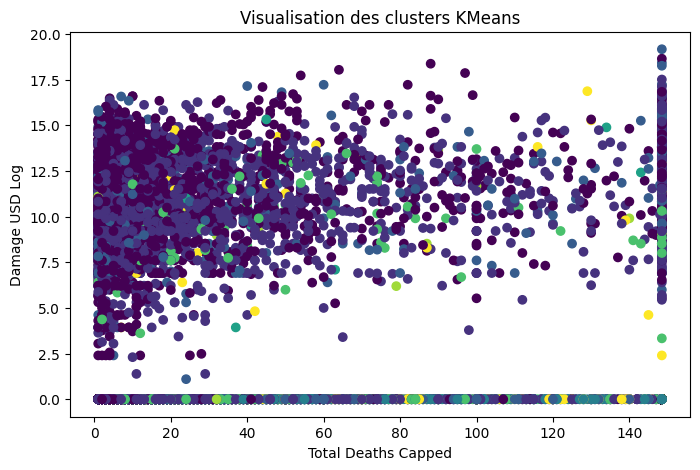

In [16]:

# Étape 16 : Visualisation des clusters

plt.figure(figsize=(8, 5))
plt.scatter(df["Total_Deaths_Capped"], df["Damage_Log"], c=df["Cluster"])
plt.title("Visualisation des clusters KMeans")
plt.xlabel("Total Deaths Capped")
plt.ylabel("Damage USD Log")
plt.show()



# Partie 2 : Classification avec plusieurs splits

La classification est une méthode supervisée.  
L'objectif est de prédire la variable `Severe`.

Dans cette version, nous utilisons **plusieurs splits**.  
Cela signifie que nous répétons l'entraînement et l'évaluation avec plusieurs valeurs de `random_state`.

Cette méthode permet d'obtenir une évaluation plus fiable que l'utilisation d'un seul split.


## 17. Sélection des variables pour la classification

La cible `Severe` est créée à partir de `Total_Deaths`. Nous excluons donc cette colonne des variables explicatives afin d'éviter une fuite directe de la cible (*target leakage*).

Variables utilisées :

- `Damage_Log`
- `Year`
- les colonnes encodées correspondant au type de catastrophe

`Decade` est exclue car elle est dérivée de `Year` et apporte une information redondante.


In [17]:
# Étape 17 : Sélection des variables pour la classification

classification_features = ["Damage_Log", "Year"] + disaster_type_columns
X = df[classification_features].copy()
y = df["Severe"].copy()

print("Nombre de variables pour la classification :", len(classification_features))
print("\nDistribution de la variable cible :")
print(y.value_counts())
print("\nProportions de la variable cible :")
print(y.value_counts(normalize=True))


Nombre de variables pour la classification : 14

Distribution de la variable cible :
Severe
0    9342
1    2071
Name: count, dtype: int64

Proportions de la variable cible :
Severe
0    0.81854
1    0.18146
Name: proportion, dtype: float64



## 18. Création des modèles

Nous comparons plusieurs modèles :

- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting avec Early Stopping

Le modèle Gradient Boosting utilise `n_iter_no_change=5` pour arrêter l'entraînement lorsque les performances ne s'améliorent plus.


In [18]:

# Étape 18 : Création des modèles

def create_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42),
        "Gradient Boosting avec Early Stopping": GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.1,
            validation_fraction=0.1,
            n_iter_no_change=5,
            random_state=42
        )
    }


## 19. Comparaison des modèles sur plusieurs découpages

Nous utilisons trois valeurs de `random_state` pour examiner la stabilité des résultats de validation.

Pour sélectionner le modèle, nous comparons les métriques calculées sur le **jeu de validation**. Le jeu de test final est réservé à l'évaluation finale et n'est pas utilisé pour choisir le modèle.


In [19]:
# Étape 19 : Évaluation sur plusieurs jeux de validation

seeds = [42, 7, 99]
all_results = []

numeric_columns = ["Damage_Log", "Year"]

for seed in seeds:
    print(f"\n==============================")
    print(f"Validation avec random_state = {seed}")
    print(f"==============================")

    # Jeu de test non utilisé dans cette étape : le test final sera évalué plus bas.
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.3, random_state=seed, stratify=y
    )
    X_val, _, y_val, _ = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=seed, stratify=y_temp
    )

    print("Train size :", X_train.shape)
    print("Validation size :", X_val.shape)

    # Le scaler est ajusté uniquement sur le jeu d'entraînement.
    scaler_classification = StandardScaler()
    X_train_scaled = X_train.copy()
    X_val_scaled = X_val.copy()

    X_train_scaled[numeric_columns] = scaler_classification.fit_transform(
        X_train[numeric_columns]
    )
    X_val_scaled[numeric_columns] = scaler_classification.transform(
        X_val[numeric_columns]
    )

    for name, model in create_models().items():
        model.fit(X_train_scaled, y_train)
        y_val_pred = model.predict(X_val_scaled)

        all_results.append({
            "Split": seed,
            "Model": name,
            "Validation Accuracy": accuracy_score(y_val, y_val_pred),
            "Validation Precision": precision_score(
                y_val, y_val_pred, zero_division=0
            ),
            "Validation Recall": recall_score(
                y_val, y_val_pred, zero_division=0
            ),
            "Validation F1-Score": f1_score(
                y_val, y_val_pred, zero_division=0
            )
        })

results_df = pd.DataFrame(all_results)
results_df



Validation avec random_state = 42
Train size : (7989, 14)
Validation size : (1712, 14)

Validation avec random_state = 7
Train size : (7989, 14)
Validation size : (1712, 14)

Validation avec random_state = 99
Train size : (7989, 14)
Validation size : (1712, 14)


,Split,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-Score
0,42,Logistic Regression,0.695678,0.337461,0.700965,0.455590
1,42,Decision Tree,0.723131,0.332649,0.520900,0.406015
2,42,Random Forest,0.759930,0.369110,0.453376,0.406926
3,42,Gradient Boosting avec Early Stopping,0.827103,0.560000,0.225080,0.321101
4,7,Logistic Regression,0.688084,0.326625,0.680645,0.441423
5,7,Decision Tree,0.723715,0.331959,0.519355,0.405031
6,7,Random Forest,0.752336,0.356784,0.458065,0.401130
7,7,Gradient Boosting avec Early Stopping,0.833528,0.612613,0.219355,0.323040
8,99,Logistic Regression,0.694509,0.335394,0.700000,0.453501
9,99,Decision Tree,0.715537,0.324056,0.525806,0.400984


## 20. Moyenne des performances de validation

Nous calculons la moyenne et l'écart-type des métriques sur les trois découpages.

Le modèle est sélectionné selon la moyenne du **F1-score de validation**, et non selon les performances du jeu de test.


In [20]:
# Étape 20 : Synthèse des performances de validation

summary_results = results_df.groupby("Model").agg(
    Validation_Accuracy_Mean=("Validation Accuracy", "mean"),
    Validation_Accuracy_Std=("Validation Accuracy", "std"),
    Validation_Precision_Mean=("Validation Precision", "mean"),
    Validation_Recall_Mean=("Validation Recall", "mean"),
    Validation_F1_Mean=("Validation F1-Score", "mean"),
    Validation_F1_Std=("Validation F1-Score", "std")
).reset_index()

summary_results = summary_results.sort_values(
    by="Validation_F1_Mean", ascending=False
).reset_index(drop=True)

summary_results


,Model,Validation_Accuracy_Mean,Validation_Accuracy_Std,Validation_Precision_Mean,Validation_Recall_Mean,Validation_F1_Mean,Validation_F1_Std
0,Logistic Regression,0.692757,0.004089,0.333160,0.693870,0.450171,0.007648
1,Decision Tree,0.720794,0.004562,0.329554,0.522021,0.404010,0.002666
2,Random Forest,0.752531,0.007303,0.357907,0.458652,0.401949,0.004623
3,Gradient Boosting avec Early Stopping,0.829634,0.003423,0.588545,0.202984,0.300572,0.037249


## 21. Sélection du meilleur modèle

Le modèle retenu est celui dont le **F1-score moyen sur les jeux de validation** est le plus élevé. Les résultats du jeu de test final ne servent pas à cette sélection.


In [21]:
# Étape 21 : Sélection du meilleur modèle

best_model_name = summary_results.iloc[0]["Model"]

print("Meilleur modèle selon le F1-score de validation :", best_model_name)
print("\nPerformances moyennes de validation :")
print(summary_results.iloc[0])


Meilleur modèle selon le F1-score de validation : Logistic Regression

Performances moyennes de validation :
Model                        Logistic Regression
Validation_Accuracy_Mean                0.692757
Validation_Accuracy_Std                 0.004089
Validation_Precision_Mean                0.33316
Validation_Recall_Mean                   0.69387
Validation_F1_Mean                      0.450171
Validation_F1_Std                       0.007648
Name: 0, dtype: object


## 22. Évaluation finale du modèle sélectionné

Après la sélection sur les jeux de validation, nous évaluons le modèle une seule fois sur un jeu de test réservé.

Pour utiliser davantage de données lors de l'entraînement final, les jeux d'entraînement et de validation du découpage final sont réunis. Le scaler est ajusté sur cet ensemble combiné, puis appliqué au jeu de test.


In [22]:
# Étape 22 : Évaluation finale sur un jeu de test réservé

final_seed = 42

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=final_seed, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=final_seed, stratify=y_temp
)

# Réunir train et validation pour l'entraînement final.
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

scaler_final = StandardScaler()
X_train_final_scaled = X_train_final.copy()
X_test_scaled = X_test.copy()

X_train_final_scaled[numeric_columns] = scaler_final.fit_transform(
    X_train_final[numeric_columns]
)
X_test_scaled[numeric_columns] = scaler_final.transform(
    X_test[numeric_columns]
)

final_models = create_models()
best_model = final_models[best_model_name]
best_model.fit(X_train_final_scaled, y_train_final)
final_predictions = best_model.predict(X_test_scaled)

print("--- Modèle final :", best_model_name, "---")
print("Accuracy :", accuracy_score(y_test, final_predictions))
print("Precision :", precision_score(y_test, final_predictions, zero_division=0))
print("Recall :", recall_score(y_test, final_predictions, zero_division=0))
print("F1-score :", f1_score(y_test, final_predictions, zero_division=0))

print("\n--- Rapport de classification ---")
print(classification_report(y_test, final_predictions, zero_division=0))

cm = confusion_matrix(y_test, final_predictions)
print("--- Matrice de confusion ---")
print(cm)


--- Modèle final : Logistic Regression ---
Accuracy : 0.697429906542056
Precision : 0.34523809523809523
Recall : 0.7483870967741936
F1-score : 0.4725050916496945

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.93      0.69      0.79      1402
           1       0.35      0.75      0.47       310

    accuracy                           0.70      1712
   macro avg       0.64      0.72      0.63      1712
weighted avg       0.82      0.70      0.73      1712

--- Matrice de confusion ---
[[962 440]
 [ 78 232]]



## 23. Visualisation de la matrice de confusion

La matrice de confusion permet de voir les bonnes prédictions et les erreurs du meilleur modèle.


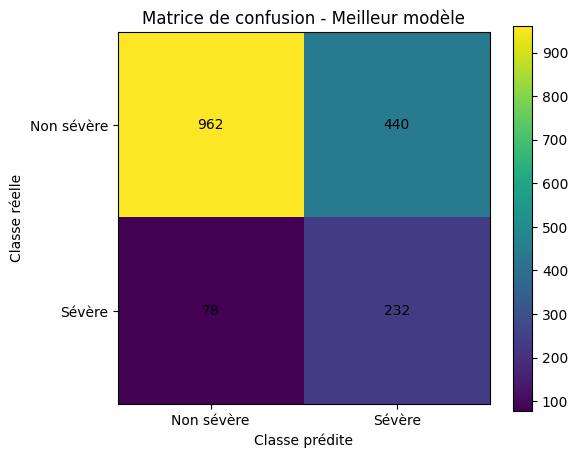

In [23]:

# Étape 23 : Affichage graphique de la matrice de confusion

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Matrice de confusion - Meilleur modèle")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xticks([0, 1], ["Non sévère", "Sévère"])
plt.yticks([0, 1], ["Non sévère", "Sévère"])
plt.show()
